In [58]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from keras.models import Sequential
from keras.layers import LSTM, Dense, Dropout

In [59]:
# List of file paths to your CSV files
file_paths = ['E:\\project_work\\dehradun 2015-01-01 to 2015-12-31.csv', 
              'E:\\project_work\\dehradun 2016-01-01 to 2017-12-31.csv', 
              'E:\\project_work\\dehradun 2018-01-01 to 2019-12-31.csv', 
              'E:\\project_work\\dehradun 2020-01-01 to 2021-12-31.csv', 
              'E:\\project_work\\dehradun 2022-01-01 to 2023-12-31.csv']
# Initialize an empty list to store the dataframes
dfs = []

# Loop through each file and read it into a DataFrame
for file in file_paths:
    df = pd.read_csv(file)
    dfs.append(df)

# Concatenate all the DataFrames into a single DataFrame
full_data = pd.concat(dfs, ignore_index=True)

# Convert 'datetime' column to datetime type if it's not already
full_data['datetime'] = pd.to_datetime(full_data['datetime'])

# Sort the data by the 'datetime' column
full_data = full_data.sort_values(by='datetime')

# save the csv
# full_data.to_csv('edited_weather_data.csv', index=False)

full_data = full_data.drop(['name', 'feelslikemax', "feelslikemin", "precipcover", "preciptype", "severerisk", "moonphase", "conditions", "description", "icon","stations", "snow", "snowdepth", 'uvindex','precip', 'windspeed','precipprob','cloudcover','visibility', 'winddir'], axis=1)



In [60]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# Assuming you have loaded your full_data DataFrame
# removed windgust, solar..,sealevelpressure
# 1. Display descriptive statistics
print(full_data.describe())

# 2. Convert 'datetime' to datetime object
full_data['datetime'] = pd.to_datetime(full_data['datetime'])

# 3. Check for missing values
print(full_data.isnull().sum())

# 4. Fill missing values or drop rows/columns as needed
# full_data = full_data.ffill()  # Forward filling

# Ensure any missing values in visibility are handled
# full_data = full_data.assign(visibility=full_data['visibility'].fillna(full_data['visibility'].mean()))

# 5. Encode 'precipprob' to binary
# full_data['precipprob'] = full_data['precipprob'].apply(lambda x: 1 if x == 100 else 0)

# 6. Normalize 'temp' using MinMaxScaler
temp_scaler = MinMaxScaler()
full_data[['temp']] = temp_scaler.fit_transform(full_data[['temp']])

# 7. Normalize other features using MinMaxScaler
# scaler = MinMaxScaler()
# full_data[['temp', 'tempmax', 'tempmin', 'feelslike', 'dew', 'humidity',
#            'precip', 'precipprob', 'windspeed',
#            'cloudcover', 'visibility', 'windgust', 'solarradiation', 'solarenergy', 'uvindex', 'sealevelpressure']] = scaler.fit_transform(
#                full_data[['temp', 'tempmax', 'tempmin', 'feelslike', 'dew', 'humidity',
#                           'precip', 'precipprob', 'windspeed', 'windgust', 'solarradiation', 'solarenergy', 'uvindex', 'sealevelpressure',
#                           'cloudcover', 'visibility']]
#            )
scaler = MinMaxScaler()
full_data[['temp', 'tempmax', 'tempmin', 'feelslike', 'dew', 'humidity',
            'windgust', 'solarradiation', 'solarenergy', 'sealevelpressure']] = scaler.fit_transform(
               full_data[['temp', 'tempmax', 'tempmin', 'feelslike', 'dew', 'humidity',
                            'windgust', 'solarradiation', 'solarenergy', 'sealevelpressure',
                           ]]
           )
# 8. Normalize wind direction
# full_data['winddir_rad'] = np.deg2rad(full_data['winddir'])  # Convert to radians
# full_data['winddir_sin'] = np.sin(full_data['winddir_rad'])  # Sine transformation
# full_data['winddir_cos'] = np.cos(full_data['winddir_rad'])  # Cosine transformation

# 9. Preprocess sunrise and sunset times
# Convert 'sunrise' and 'sunset' to datetime objects
full_data['sunrise'] = pd.to_datetime(full_data['sunrise'])
full_data['sunset'] = pd.to_datetime(full_data['sunset'])

# Calculate minutes since midnight for sunrise and sunset
full_data['sunrise_minutes'] = full_data['sunrise'].dt.hour * 60 + full_data['sunrise'].dt.minute
full_data['sunset_minutes'] = full_data['sunset'].dt.hour * 60 + full_data['sunset'].dt.minute

# Normalize sunrise and sunset minutes
full_data[['sunrise_minutes', 'sunset_minutes']] = scaler.fit_transform(
    full_data[['sunrise_minutes', 'sunset_minutes']]
)

# 10. Drop unnecessary columns
full_data.drop(['datetime', 'sunrise', 'sunset'], axis=1, inplace=True)

# 11. Display descriptive statistics for the normalized data
print(full_data[['temp', 'tempmax', 'tempmin', 'sunrise_minutes', 'sunset_minutes']].describe())


                            datetime      tempmax      tempmin         temp  \
count                           3287  3287.000000  3287.000000  3287.000000   
mean   2019-07-01 23:59:59.999999744    28.852297    16.472224    21.851202   
min              2015-01-01 00:00:00    11.400000     1.100000     7.800000   
25%              2017-04-01 12:00:00    24.950000    10.700000    16.500000   
50%              2019-07-02 00:00:00    29.800000    17.400000    23.700000   
75%              2021-09-30 12:00:00    32.600000    22.700000    26.900000   
max              2023-12-31 00:00:00    43.600000    27.700000    35.300000   
std                              NaN     5.600972     6.551562     6.180714   

         feelslike          dew     humidity     windgust  sealevelpressure  \
count  3287.000000  3287.000000  3287.000000  3287.000000       3287.000000   
mean     22.413264    14.627502    68.415972    24.023213       1008.922939   
min       7.800000    -3.600000    18.700000     4.

In [61]:
file_path = "processed_data.csv"
full_data.to_csv(file_path, index=False)

In [62]:
import numpy as np

# Function to create sequences
def create_sequences(data, target_column, time_steps):
    sequences = []
    targets = []

    for i in range(len(data) - time_steps):
        seq = data.iloc[i:i + time_steps].values  # Create sequence
        target = data.iloc[i + time_steps][target_column]  # Target value
        sequences.append(seq)
        targets.append(target)

    return np.array(sequences), np.array(targets)

# Define your target variable and time steps
target_column = 'temp'  # Change this if you want to predict a different variable
time_steps = 8  # Adjust this according to your needs

# Create sequences
X, y = create_sequences(full_data, target_column, time_steps)

# Print the shape of the sequences
print("Shape of X:", X.shape)  # (number_of_samples, time_steps, number_of_features)
print("Shape of y:", y.shape)  # (number_of_samples,)


Shape of X: (3279, 8, 12)
Shape of y: (3279,)


In [63]:

from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

# # Further split training into training and validation sets
# X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, shuffle=False)
# Time-based split (assuming data is sorted by time)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, shuffle=False)  # 80% for training
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, shuffle=False)  # 50% of the remaining for validation and test

print("Training set shape:", X_train.shape, y_train.shape)
print("Validation set shape:", X_val.shape, y_val.shape)
print("Test set shape:", X_test.shape, y_test.shape)


Training set shape: (2623, 8, 12) (2623,)
Validation set shape: (328, 8, 12) (328,)
Test set shape: (328, 8, 12) (328,)


In [64]:
from keras.models import Sequential
from keras.layers import Conv1D, MaxPooling1D, BatchNormalization, LSTM, Dropout, Dense
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping

In [65]:
# # Define the model architecture with the current hyperparameters
# model = Sequential()
# # Update the Conv1D input_shape to match the data
# model.add(Conv1D(filters=128, kernel_size=5, activation='relu', input_shape=(8, 14)))
# model.add(MaxPooling1D(pool_size=2))
# # model.add(BatchNormalization())

# model.add(LSTM(200, return_sequences=True))
# model.add(Dropout(0.22470767944910103))
# model.add(LSTM(400))
# model.add(Dropout(0.2941000186185122))

# model.add(Dense(1))  # Regression output layer

# # Compile the model with the current learning rate
# optimizer = Adam(learning_rate=0.01)
# model.compile(optimizer=optimizer, loss='mean_squared_error', metrics=['mae'])

# # Define the model architecture with the current hyperparameters
# model = Sequential()
# # Update the Conv1D input_shape to match the data
# model.add(Conv1D(filters=82, kernel_size=3, activation='relu', input_shape=(8, 14)))
# model.add(MaxPooling1D(pool_size=2))
# # model.add(BatchNormalization())

# model.add(LSTM(200, return_sequences=True))
# model.add(Dropout(0.42760592399639485))
# model.add(LSTM(400))
# model.add(Dropout(0.1555185575054211))

# model.add(Dense(1))  # Regression output layer

# # Compile the model with the current learning rate
# optimizer = Adam(learning_rate=0.008750471246304323)
# model.compile(optimizer=optimizer, loss='mean_squared_error', metrics=['mae'])

# Define the model architecture with the current hyperparameters
model = Sequential()
# Update the Conv1D input_shape to match the data
model.add(Conv1D(filters=82, kernel_size=3, activation='relu', input_shape=(8, 12)))
model.add(MaxPooling1D(pool_size=2))
# model.add(BatchNormalization())

model.add(LSTM(300, return_sequences=True))
model.add(Dropout(0.164235338780274))
model.add(LSTM(400))
model.add(Dropout(0.34377197804621473))

model.add(Dense(1))  # Regression output layer

# Compile the model with the current learning rate
optimizer = Adam(learning_rate=0.0053739015411619325)
model.compile(optimizer=optimizer, loss='mean_squared_error', metrics=['mae'])

C:\Users\ayush\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [66]:
# Add early stopping
early_stopping = EarlyStopping(
    monitor='val_loss',  # Monitor validation loss
    patience=40,         # Stop training after 40 epochs with no improvement
    restore_best_weights=True  # Restore weights from the epoch with the best validation loss
)

# Train the model with the given batch size and hyperparameters
history = model.fit(
    X_train, y_train, 
    epochs=200, 
    batch_size=64, 
    validation_data=(X_val, y_val), 
    verbose=1,
    callbacks=[early_stopping]  # Include early stopping in the callbacks
)

Epoch 1/200
41/41 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - loss: 0.1762 - mae: 0.3271 - val_loss: 0.0062 - val_mae: 0.0638
Epoch 2/200
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0053 - mae: 0.0574 - val_loss: 0.0049 - val_mae: 0.0561
Epoch 3/200
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0047 - mae: 0.0533 - val_loss: 0.0062 - val_mae: 0.0646
Epoch 4/200
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0043 - mae: 0.0512 - val_loss: 0.0042 - val_mae: 0.0505
Epoch 5/200
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0041 - mae: 0.0500 - val_loss: 0.0047 - val_mae: 0.0555
Epoch 6/200
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0039 - mae: 0.0484 - val_loss: 0.0035 - val_mae: 0.0459
Epoch 7/200
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0037 - mae: 0.0468 - val_loss: 0.0047 - val_mae: 0.0534
Epoch 8/200
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0035 - mae: 0.0460 - val_loss: 0.0035 - val_mae: 0.0468
Epoch 9/200
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - lo

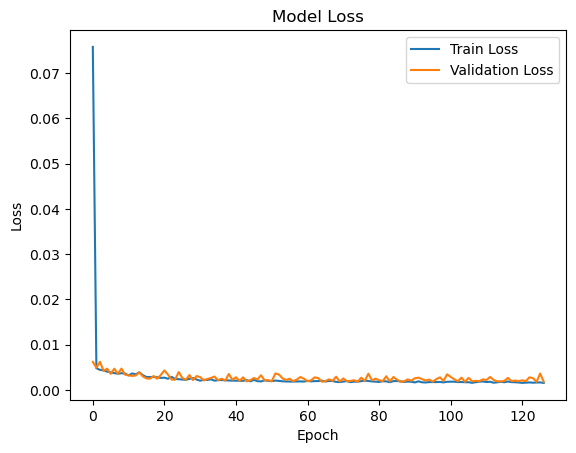

In [67]:
import matplotlib.pyplot as plt
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.show()

In [68]:
from tensorflow.keras.models import load_model

# Load the model
# model = load_model('C:\\Users\\ayush\\OneDrive\\Desktop\\conda\\80_model.h5')


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0021 - mae: 0.0324 
Test Loss: [0.0016893268330022693, 0.028785794973373413]
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step
Evaluation Metrics:
Mean Absolute Error (MAE): 0.7916092919140328
Mean Squared Error (MSE): 1.2775537526478091
Root Mean Squared Error (RMSE): 1.1302892340670192
R-squared (R²): 0.9429340600753154
Mean Bias Deviation (MBD): 0.3173965242839643%


E:\conda\Lib\site-packages\sklearn\metrics\_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


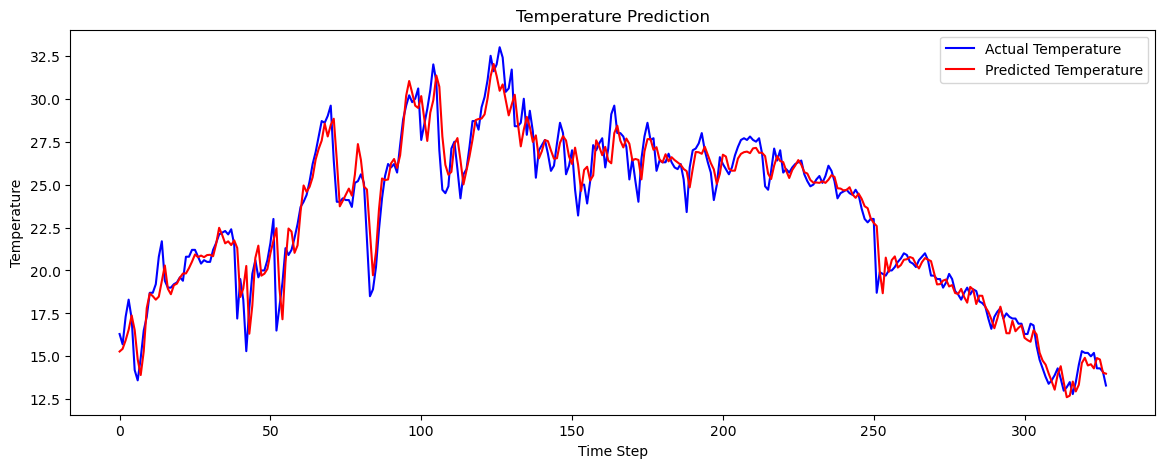

In [69]:
# Evaluate the model on the test set
test_loss = model.evaluate(X_test, y_test)
print(f'Test Loss: {test_loss}')

# Make predictions
predictions = model.predict(X_test)

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Inverse transform predictions and true values using the temp_scaler
predictions_original = temp_scaler.inverse_transform(predictions)  # No need to reshape
y_test_original = temp_scaler.inverse_transform(y_test.reshape(-1, 1))  # Reshape if necessary

# Import necessary libraries
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt

# Calculate evaluation metrics
mae = mean_absolute_error(y_test_original, predictions_original)
mse = mean_squared_error(y_test_original, predictions_original)
rmse = mean_squared_error(y_test_original, predictions_original, squared=False)
r_squared = r2_score(y_test_original, predictions_original)
mbd = np.mean((predictions_original - y_test_original) / y_test_original) * 100

# Print the evaluation results
print("Evaluation Metrics:")
print(f"Mean Absolute Error (MAE): {mae}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"Root Mean Squared Error (RMSE): {rmse}")
print(f"R-squared (R²): {r_squared}")
print(f"Mean Bias Deviation (MBD): {mbd}%")

# Plot predictions vs actual
plt.figure(figsize=(14, 5))
plt.plot(y_test_original, label='Actual Temperature', color='blue')  # Actual temperatures
plt.plot(predictions_original, label='Predicted Temperature', color='red')  # Predicted temperatures
plt.title('Temperature Prediction')
plt.xlabel('Time Step')
plt.ylabel('Temperature')
plt.legend()
plt.show()

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 


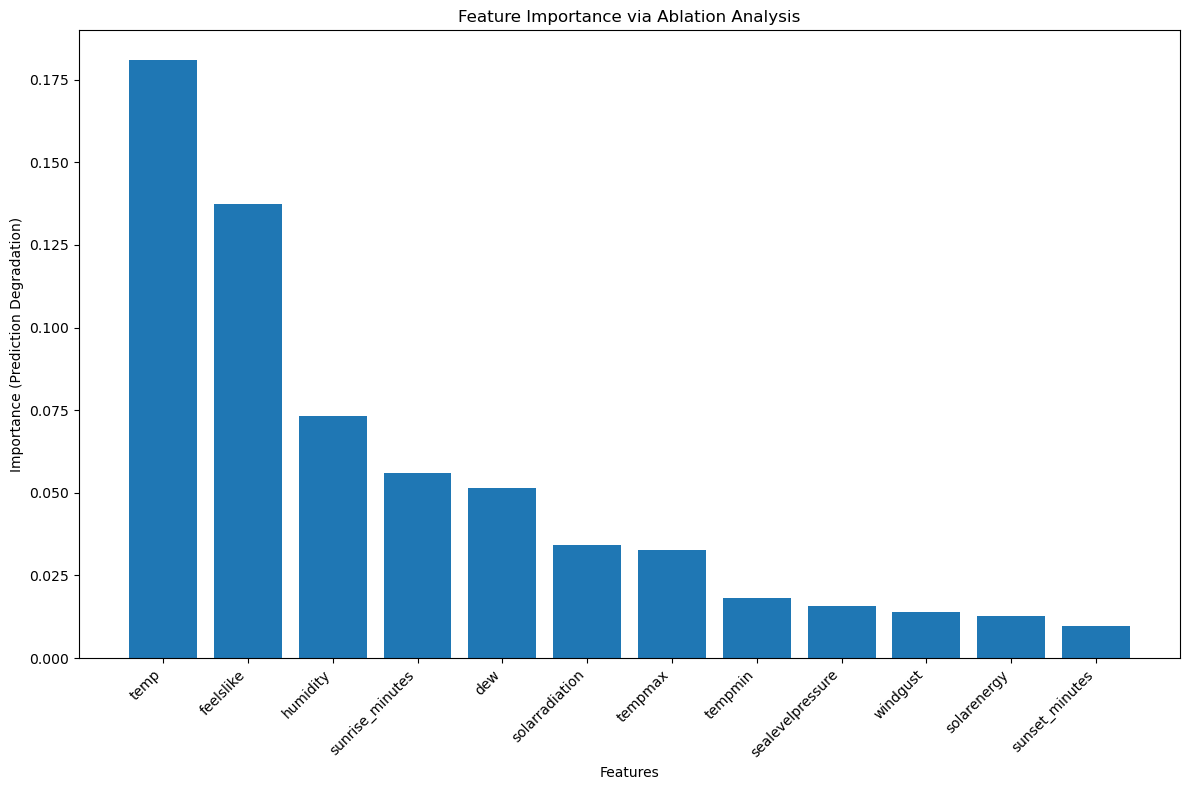

In [70]:
def feature_ablation_importance(model, X_val, y_val, feature_names, baseline='zero'):
    """
    Compute feature importance via ablation analysis.

    Parameters:
        model: Trained LSTM model
        X_val: Validation set (3D: samples, time steps, features)
        y_val: True labels for the validation set
        feature_names: List of feature names (length = number of features)
        baseline: Baseline value ('zero', 'mean', or 'random')
    
    Returns:
        importance: List of feature importances (one value per feature)
    """
    # Get the original model predictions
    baseline_preds = model.predict(X_val).flatten()
    
    # Initialize importance list
    importance = []
    
    # Loop through each feature
    for feature_idx in range(X_val.shape[2]):  # Iterate over features
        # Create a copy of the validation set
        X_temp = X_val.copy()
        
        # Apply the baseline value
        if baseline == 'zero':
            X_temp[:, :, feature_idx] = 0
        elif baseline == 'mean':
            X_temp[:, :, feature_idx] = np.mean(X_val[:, :, feature_idx])
        elif baseline == 'random':
            X_temp[:, :, feature_idx] = np.random.random(X_val[:, :, feature_idx].shape)
        else:
            raise ValueError("Baseline must be 'zero', 'mean', or 'random'")
        
        # Get predictions after ablation
        ablated_preds = model.predict(X_temp).flatten()
        
        # Measure performance degradation (mean absolute difference)
        degradation = np.mean(np.abs(baseline_preds - ablated_preds))
        importance.append(degradation)
    
    return dict(zip(feature_names, importance))
# Define feature names (replace with your actual feature names)
feature_names = ['tempmax',	'tempmin', 'temp', 'feelslike','dew', 'humidity','windgust','sealevelpressure', 'solarradiation','solarenergy', 'sunrise_minutes', 'sunset_minutes'
]

# Compute feature importances
feature_importances = feature_ablation_importance(model, X_val, y_val, feature_names, baseline='zero')

# Sort features by importance
sorted_features = sorted(feature_importances.items(), key=lambda x: x[1], reverse=True)

# Plot
plt.figure(figsize=(12, 8))
plt.bar([name for name, _ in sorted_features], [imp for _, imp in sorted_features])
plt.xlabel("Features")
plt.ylabel("Importance (Prediction Degradation)")
plt.title("Feature Importance via Ablation Analysis")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [71]:
# Save the trained model
model.save('best_weather_model.h5')  # Save as an h5 file

datetime            0
tempmax             0
tempmin             0
temp                0
feelslike           0
dew                 0
humidity            0
windgust            0
sealevelpressure    0
solarradiation      0
solarenergy         0
sunrise             0
sunset              0
dtype: int64
Shape of X_unseen: (52, 8, 12)
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 390ms/step
Mean Absolute Error (MAE): 0.809185640628521
Mean Squared Error (MSE): 1.0071954548191884
Root Mean Squared Error (RMSE): 1.0035912787679995
R-squared (R²): 0.7773678790033274
Mean Bias Deviation (MBD): 3.4685061591829083%


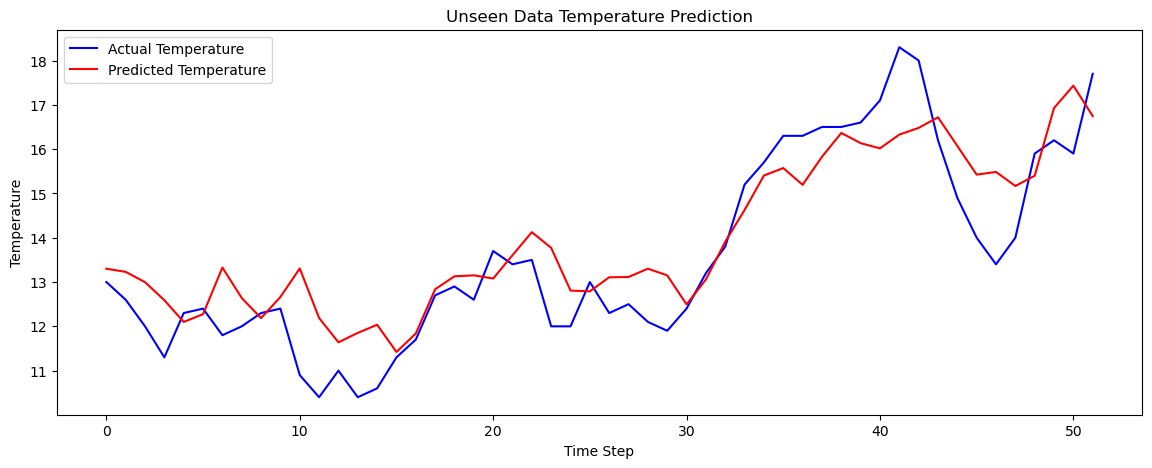

In [72]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
from keras.models import load_model

# Load unseen data


# unseen_file_path = 'E:\\project_work\\dehradun 2024-01-01 to 2024-01-31.csv'  # Replace with the actual file path
unseen_file_path = 'E:\\project_work\\dehradun 2024-01-01 to 2024-02-29.csv'
unseen_data = pd.read_csv(unseen_file_path)

# Convert 'datetime' column to datetime type
unseen_data['datetime'] = pd.to_datetime(unseen_data['datetime'])

# Sort the data by the 'datetime' column
unseen_data = unseen_data.sort_values(by='datetime')

# Drop unnecessary columns (ensure these columns exist in the unseen data)
unseen_data = unseen_data.drop(['name', 'feelslikemax', "feelslikemin", "precipcover", "preciptype",
                                "severerisk", "moonphase", "conditions", 'winddir',
                                "description", "icon", "stations", "snow", "snowdepth", 'uvindex','precip', 'windspeed','precipprob','cloudcover', 'visibility'
                                ], axis=1, errors='ignore')

# 1. Check for missing values
print(unseen_data.isnull().sum())

# 2. Fill missing values
# unseen_data = unseen_data.ffill()  # Forward fill to handle missing data
# unseen_data['visibility'] = unseen_data['visibility'].fillna(unseen_data['visibility'].mean())  # Handle missing visibility

# 3. Encode 'precipprob' to binary
# unseen_data['precipprob'] = unseen_data['precipprob'].apply(lambda x: 1 if x == 100 else 0)

# 4. Normalize 'temp' using MinMaxScaler (same as used during training)
temp_scaler = MinMaxScaler()
unseen_data[['temp']] = temp_scaler.fit_transform(unseen_data[['temp']])

# 5. Normalize other features using MinMaxScaler
# scaler = MinMaxScaler()
# unseen_data[['temp', 'tempmax', 'tempmin', 'feelslike', 'dew', 'humidity',
#              'precip', 'precipprob', 'windspeed', 'windgust', 'solarradiation', 'solarenergy', 'uvindex', 'sealevelpressure',
#               'cloudcover', 'visibility']] = scaler.fit_transform(
#                  unseen_data[['temp', 'tempmax', 'tempmin', 'feelslike', 'dew',
#                               'humidity', 'precip', 'precipprob',
#                               'windspeed', 'windgust', 'solarradiation', 'solarenergy', 'uvindex', 'sealevelpressure',
#                               'cloudcover', 'visibility']])
scaler = MinMaxScaler()
unseen_data[['temp', 'tempmax', 'tempmin', 'feelslike', 'dew', 'humidity',
               'windgust', 'solarradiation', 'solarenergy', 'sealevelpressure',
               ]] = scaler.fit_transform(
                 unseen_data[['temp', 'tempmax', 'tempmin', 'feelslike', 'dew',
                              'humidity',
                               'windgust', 'solarradiation', 'solarenergy', 'sealevelpressure',
                               ]])

# 6. Normalize wind direction
# unseen_data['winddir_rad'] = np.deg2rad(unseen_data['winddir'])  # Convert to radians
# unseen_data['winddir_sin'] = np.sin(unseen_data['winddir_rad'])  # Sine transformation
# unseen_data['winddir_cos'] = np.cos(unseen_data['winddir_rad'])  # Cosine transformation

# 7. Preprocess sunrise and sunset times
# If the unseen data contains 'sunrise' and 'sunset' columns
if 'sunrise' in unseen_data.columns and 'sunset' in unseen_data.columns:
    unseen_data['sunrise'] = pd.to_datetime(unseen_data['sunrise'])
    unseen_data['sunset'] = pd.to_datetime(unseen_data['sunset'])
    unseen_data['sunrise_minutes'] = unseen_data['sunrise'].dt.hour * 60 + unseen_data['sunrise'].dt.minute
    unseen_data['sunset_minutes'] = unseen_data['sunset'].dt.hour * 60 + unseen_data['sunset'].dt.minute

    # Normalize 'sunrise_minutes' and 'sunset_minutes'
    unseen_data[['sunrise_minutes', 'sunset_minutes']] = scaler.fit_transform(
        unseen_data[['sunrise_minutes', 'sunset_minutes']]
    )

# 8. Drop unnecessary columns
unseen_data.drop(['datetime', 'sunrise', 'sunset'], axis=1, inplace=True, errors='ignore')

# Prepare data for model prediction
# window_size = 10  # Your previous window  91% model acc(74..)
window_size = 8  # Your previous window size
X_unseen, y_unseen = [], []

for i in range(window_size, len(unseen_data)):
    X_unseen.append(unseen_data.iloc[i-window_size:i].values)
    y_unseen.append(unseen_data.iloc[i]['temp'])  # Assuming 'temp' is the target variable

X_unseen, y_unseen = np.array(X_unseen), np.array(y_unseen)

# Check the shape of X_unseen
print(f"Shape of X_unseen: {X_unseen.shape}")  # Should be (samples, window_size, features)

# Load the trained model
model = load_model('C:\\Users\\ayush\\OneDrive\\Desktop\\conda\\best_weather_model.h5')  # Replace with your model path

# Make predictions
predictions = model.predict(X_unseen)

# Inverse transform predictions and actual values for comparison
predictions_inv = temp_scaler.inverse_transform(predictions)
y_unseen_inv = temp_scaler.inverse_transform(y_unseen.reshape(-1, 1))

# Calculate evaluation metrics
mae = np.mean(np.abs(predictions_inv - y_unseen_inv))
mse = np.mean((predictions_inv - y_unseen_inv)**2)
rmse = np.sqrt(mse)
r_squared = 1 - (np.sum((predictions_inv - y_unseen_inv) ** 2) / np.sum((y_unseen_inv - np.mean(y_unseen_inv)) ** 2))

# Calculate Mean Bias Deviation (MBD)
mbd = np.mean((predictions_inv - y_unseen_inv) / y_unseen_inv) * 100

# Print the evaluation results
print(f'Mean Absolute Error (MAE): {mae}')
print(f'Mean Squared Error (MSE): {mse}')
print(f'Root Mean Squared Error (RMSE): {rmse}')
print(f'R-squared (R²): {r_squared}')
print(f'Mean Bias Deviation (MBD): {mbd}%')

# Plot predictions vs actual
plt.figure(figsize=(14, 5))
plt.plot(y_unseen_inv, label='Actual Temperature', color='blue')
plt.plot(predictions_inv, label='Predicted Temperature', color='red')
plt.title('Unseen Data Temperature Prediction')
plt.xlabel('Time Step')
plt.ylabel('Temperature')
plt.legend()
plt.show()

Differences between predicted and actual temperatures (Predicted - Actual):
[ 0.30021286  0.6297554   0.99644852  1.2892992  -0.20084934 -0.12485256
  1.52700253  0.63919926 -0.11421566  0.26307163  2.40695438  1.78797684
  0.63942337  1.45179043  1.43546047  0.12156506  0.13802032  0.13644485
  0.22940216  0.55077782 -0.62071533  0.20554123  0.62627792  1.77029324
  0.80724716 -0.2101326   0.80698223  0.61337757  1.20102825  1.25049171
  0.09519253 -0.14250965  0.11052151 -0.57322903 -0.29572029 -0.72785358
 -1.10614281 -0.67390442 -0.13479805 -0.4651619  -1.08276901 -1.97228889
 -1.52060127  0.51784592  1.17111168  1.42445183  2.08521042  1.1682806
 -0.50138321  0.72759132  1.53238068 -0.95389481]


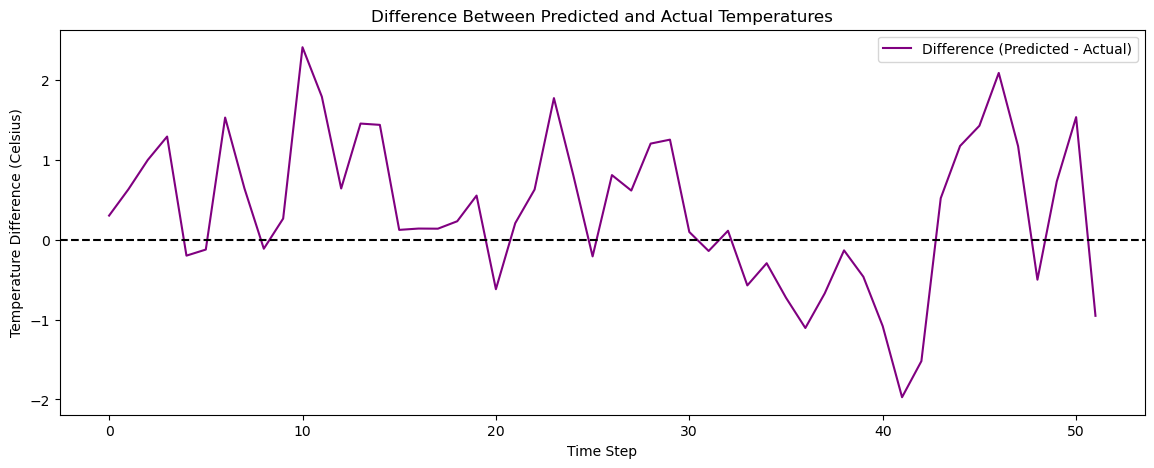

In [73]:
# Calculate the difference between predicted and actual temperatures
temperature_diff = predictions_inv.flatten() - y_unseen_inv.flatten()

# Print the differences
print("Differences between predicted and actual temperatures (Predicted - Actual):")
print(temperature_diff)

# Optionally, plot the differences to visualize the variations
plt.figure(figsize=(14, 5))
plt.plot(temperature_diff, label='Difference (Predicted - Actual)', color='purple')
plt.title('Difference Between Predicted and Actual Temperatures')
plt.xlabel('Time Step')
plt.ylabel('Temperature Difference (Celsius)')
plt.axhline(0, color='black', linestyle='--')  # Add a horizontal line at y=0 for reference
plt.legend()
plt.show()


datetime            0
tempmax             0
tempmin             0
temp                0
feelslike           0
dew                 0
humidity            0
windgust            0
sealevelpressure    0
solarradiation      0
solarenergy         0
sunrise             0
sunset              0
dtype: int64
Shape of X_unseen: (83, 8, 12)


3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 400ms/step
Mean Absolute Error (MAE): 0.8371385229639262
Mean Squared Error (MSE): 1.158844215600634
Root Mean Squared Error (RMSE): 1.0764962682706494
R-squared (R²): 0.9322274548353874
Mean Bias Deviation (MBD): 1.486223047659836%


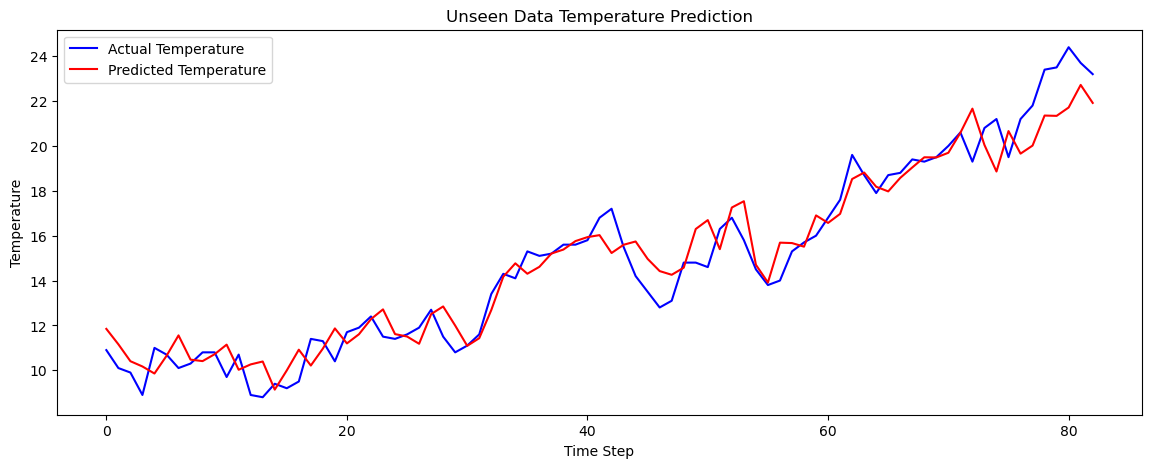

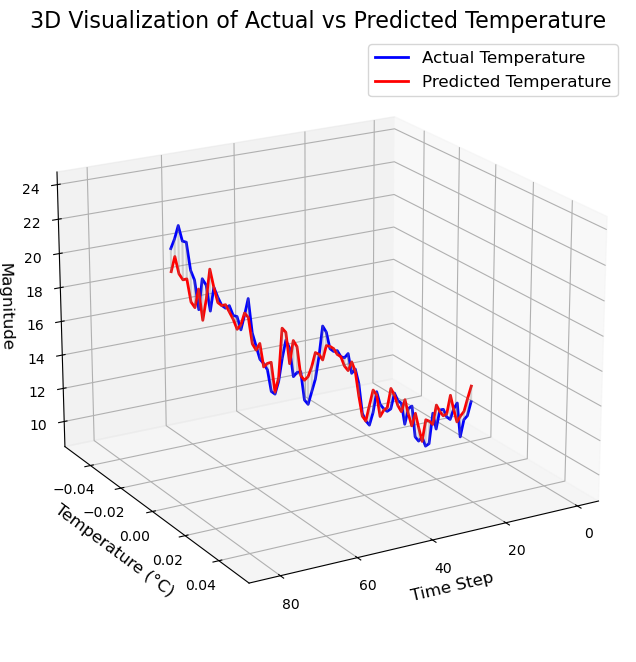

In [74]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
from keras.models import load_model

# Load unseen data


# unseen_file_path = 'E:\\project_work\\dehradun 2024-01-01 to 2024-01-31.csv'  # Replace with the actual file path
unseen_file_path = "E:\\project_work\\dehradun 2024-01-01 to 2024-03-31.csv"
unseen_data = pd.read_csv(unseen_file_path)

# Convert 'datetime' column to datetime type
unseen_data['datetime'] = pd.to_datetime(unseen_data['datetime'])

# Sort the data by the 'datetime' column
unseen_data = unseen_data.sort_values(by='datetime')
4
# Drop unnecessary columns (ensure these columns exist in the unseen data)
unseen_data = unseen_data.drop(['name', 'feelslikemax', "feelslikemin", "precipcover", "preciptype",
                                "severerisk", "moonphase", "conditions", 'winddir',
                                "description", "icon", "stations", "snow", "snowdepth", 'uvindex', 'windspeed','precip','precipprob','cloudcover','visibility'
                               ], axis=1, errors='ignore')

# 1. Check for missing values
print(unseen_data.isnull().sum())

# 2. Fill missing values
# unseen_data = unseen_data.ffill()  # Forward fill to handle missing data
# unseen_data['visibility'] = unseen_data['visibility'].fillna(unseen_data['visibility'].mean())  # Handle missing visibility

# 3. Encode 'precipprob' to binary
# unseen_data['precipprob'] = unseen_data['precipprob'].apply(lambda x: 1 if x == 100 else 0)

# 4. Normalize 'temp' using MinMaxScaler (same as used during training)
temp_scaler = MinMaxScaler()
unseen_data[['temp']] = temp_scaler.fit_transform(unseen_data[['temp']])

# # 5. Normalize other features using MinMaxScaler
# scaler = MinMaxScaler()
# unseen_data[['temp', 'tempmax', 'tempmin', 'feelslike', 'dew', 'humidity',
#              'precip', 'precipprob', 'windspeed', 'windgust', 'solarradiation', 'solarenergy', 'uvindex', 'sealevelpressure',
#               'cloudcover', 'visibility']] = scaler.fit_transform(
#                  unseen_data[['temp', 'tempmax', 'tempmin', 'feelslike', 'dew',
#                               'humidity', 'precip', 'precipprob',
#                               'windspeed', 'windgust', 'solarradiation', 'solarenergy', 'uvindex', 'sealevelpressure',
#                               'cloudcover', 'visibility']])

scaler = MinMaxScaler()
unseen_data[['temp', 'tempmax', 'tempmin', 'feelslike', 'dew', 'humidity',
              'windgust', 'solarradiation', 'solarenergy', 'sealevelpressure',
               ]] = scaler.fit_transform(
                 unseen_data[['temp', 'tempmax', 'tempmin', 'feelslike', 'dew',
                              'humidity',
                               'windgust', 'solarradiation', 'solarenergy', 'sealevelpressure',
                               ]])
# 6. Normalize wind direction
# unseen_data['winddir_rad'] = np.deg2rad(unseen_data['winddir'])  # Convert to radians
# unseen_data['winddir_sin'] = np.sin(unseen_data['winddir_rad'])  # Sine transformation
# unseen_data['winddir_cos'] = np.cos(unseen_data['winddir_rad'])  # Cosine transformation

# 7. Preprocess sunrise and sunset times
# If the unseen data contains 'sunrise' and 'sunset' columns
if 'sunrise' in unseen_data.columns and 'sunset' in unseen_data.columns:
    unseen_data['sunrise'] = pd.to_datetime(unseen_data['sunrise'])
    unseen_data['sunset'] = pd.to_datetime(unseen_data['sunset'])
    unseen_data['sunrise_minutes'] = unseen_data['sunrise'].dt.hour * 60 + unseen_data['sunrise'].dt.minute
    unseen_data['sunset_minutes'] = unseen_data['sunset'].dt.hour * 60 + unseen_data['sunset'].dt.minute

    # Normalize 'sunrise_minutes' and 'sunset_minutes'
    unseen_data[['sunrise_minutes', 'sunset_minutes']] = scaler.fit_transform(
        unseen_data[['sunrise_minutes', 'sunset_minutes']]
    )

# 8. Drop unnecessary columns
unseen_data.drop(['datetime', 'sunrise', 'sunset'], axis=1, inplace=True, errors='ignore')

# Prepare data for model prediction
# window_size = 6  # Your previous window size 91% model acc(93..)
window_size = 8  # Your previous window size
X_unseen, y_unseen = [], []

for i in range(window_size, len(unseen_data)):
    X_unseen.append(unseen_data.iloc[i-window_size:i].values)
    y_unseen.append(unseen_data.iloc[i]['temp'])  # Assuming 'temp' is the target variable

X_unseen, y_unseen = np.array(X_unseen), np.array(y_unseen)

# Check the shape of X_unseen
print(f"Shape of X_unseen: {X_unseen.shape}")  # Should be (samples, window_size, features)

# Load the trained model
model = load_model('C:\\Users\\ayush\\OneDrive\\Desktop\\conda\\best_weather_model.h5')  # Replace with your model path

# Make predictions
predictions = model.predict(X_unseen)

# Inverse transform predictions and actual values for comparison
predictions_inv = temp_scaler.inverse_transform(predictions)
y_unseen_inv = temp_scaler.inverse_transform(y_unseen.reshape(-1, 1))

# Calculate evaluation metrics
mae = np.mean(np.abs(predictions_inv - y_unseen_inv))
mse = np.mean((predictions_inv - y_unseen_inv)**2)
rmse = np.sqrt(mse)
r_squared = 1 - (np.sum((predictions_inv - y_unseen_inv) ** 2) / np.sum((y_unseen_inv - np.mean(y_unseen_inv)) ** 2))

# Calculate Mean Bias Deviation (MBD)
mbd = np.mean((predictions_inv - y_unseen_inv) / y_unseen_inv) * 100

# Print the evaluation results
print(f'Mean Absolute Error (MAE): {mae}')
print(f'Mean Squared Error (MSE): {mse}')
print(f'Root Mean Squared Error (RMSE): {rmse}')
print(f'R-squared (R²): {r_squared}')
print(f'Mean Bias Deviation (MBD): {mbd}%')

# Plot predictions vs actual
plt.figure(figsize=(14, 5))
plt.plot(y_unseen_inv, label='Actual Temperature', color='blue')
plt.plot(predictions_inv, label='Predicted Temperature', color='red')
plt.title('Unseen Data Temperature Prediction')
plt.xlabel('Time Step')
plt.ylabel('Temperature')
plt.legend()
plt.show()
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

# Sample data
z_values = np.arange(len(y_unseen_inv))  # Time step
actual = y_unseen_inv.flatten()
predicted = predictions_inv.flatten()
error = np.abs(actual - predicted)

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Smooth line plots for actual and predicted values
ax.plot(z_values, actual, zs=0, zdir='y', label='Actual Temperature', color='blue', linewidth=2)
ax.plot(z_values, predicted, zs=0, zdir='y', label='Predicted Temperature', color='red', linewidth=2)

# Shaded error area
for i in range(len(z_values)):
    ax.plot([z_values[i], z_values[i]], [actual[i], predicted[i]], zs=0, zdir='y', color='gray', alpha=0.3)

# Enhancing readability
ax.set_title("3D Visualization of Actual vs Predicted Temperature", fontsize=16)
ax.set_xlabel("Time Step", fontsize=12)
ax.set_ylabel("Temperature (°C)", fontsize=12)
ax.set_zlabel("Magnitude", fontsize=12)

# Adjust view and add legend
ax.view_init(elev=20, azim=60)
ax.legend(fontsize=12)

plt.show()

Differences between predicted and actual temperatures (Predicted - Actual):
[ 0.94598446  1.05941715  0.50533829  1.27029476 -1.14365101 -0.05760689
  1.45634212  0.17545624 -0.3900898  -0.08387165  1.44407539 -0.6756813
  1.3631731   1.59226151 -0.2615818   0.79452496  1.41838264 -1.18781796
 -0.33297138  1.46655712 -0.50141544 -0.2934536  -0.11863079  1.21570683
  0.21306095 -0.09476433 -0.71782818 -0.19443531  1.34582996  1.19418449
 -0.0101553  -0.16877899 -0.71654453 -0.12929134  0.66753044 -0.99598579
 -0.48807487  0.00321274 -0.21747646  0.15923157  0.13605232 -0.7754982
 -1.97200413  0.09496117  1.54171925  1.4655714   1.62234325  1.15692463
 -0.22644691  1.49825783  2.0948719  -0.90152531  0.45574493  1.73667641
  0.20335674  0.11412926  1.6893177   0.37083073 -0.18944473  0.90414429
 -0.23097305 -0.62685356 -1.07392082  0.1148613   0.28079185 -0.72584076
 -0.22320633 -0.35883751  0.19406052 -0.01316071 -0.30412483 -0.01266251
  2.36255379 -0.75718956 -2.33993835  1.16237068 -

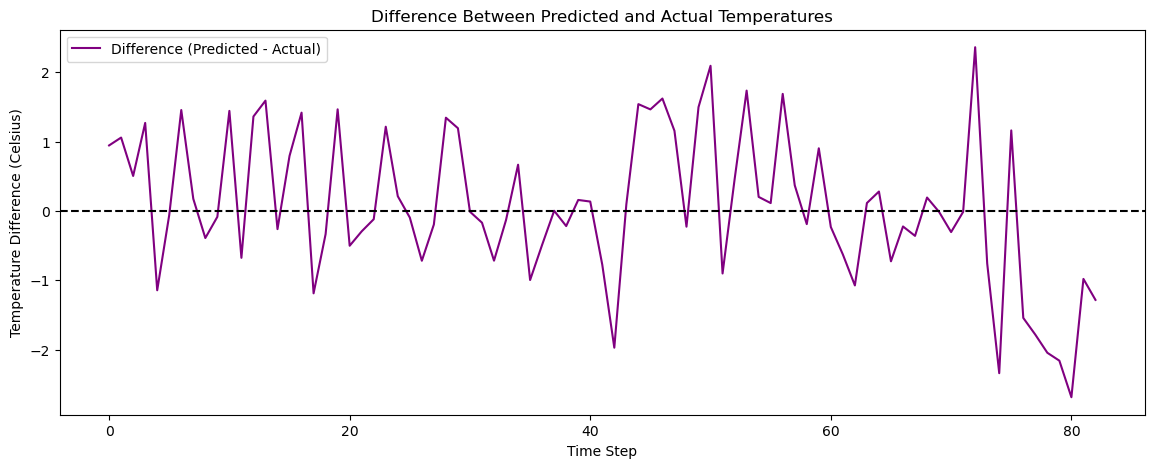

In [75]:
# Calculate the difference between predicted and actual temperatures
temperature_diff = predictions_inv.flatten() - y_unseen_inv.flatten()

# Print the differences
print("Differences between predicted and actual temperatures (Predicted - Actual):")
print(temperature_diff)

# Optionally, plot the differences to visualize the variations
plt.figure(figsize=(14, 5))
plt.plot(temperature_diff, label='Difference (Predicted - Actual)', color='purple')
plt.title('Difference Between Predicted and Actual Temperatures')
plt.xlabel('Time Step')
plt.ylabel('Temperature Difference (Celsius)')
plt.axhline(0, color='black', linestyle='--')  # Add a horizontal line at y=0 for reference
plt.legend()
plt.show()


datetime            0
tempmax             0
tempmin             0
temp                0
feelslike           0
dew                 0
humidity            0
precip              0
precipprob          0
windgust            0
windspeed           0
winddir             0
sealevelpressure    0
cloudcover          0
visibility          4
solarradiation      0
solarenergy         0
uvindex             0
sunrise             0
sunset              0
dtype: int64
Shape of X_unseen: (76, 15, 21)


3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 148ms/step
Mean Absolute Error (MAE): 0.8394568618975186
Mean Squared Error (MSE): 1.1670196437753133
Root Mean Squared Error (RMSE): 1.080286834028497
R-squared (R²): 0.9292429901213376
Mean Bias Deviation (MBD): 2.1952246830952338%


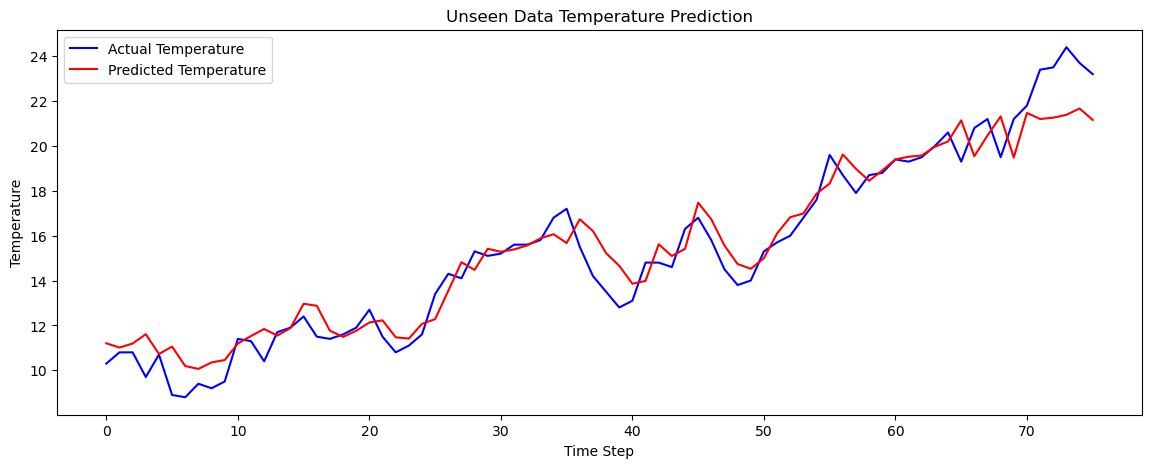

In [76]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
from keras.models import load_model

# Load unseen data


# unseen_file_path = 'E:\\project_work\\dehradun 2024-01-01 to 2024-01-31.csv'  # Replace with the actual file path
unseen_file_path = "E:\\project_work\\dehradun 2024-01-01 to 2024-03-31.csv"
unseen_data = pd.read_csv(unseen_file_path)

# Convert 'datetime' column to datetime type
unseen_data['datetime'] = pd.to_datetime(unseen_data['datetime'])

# Sort the data by the 'datetime' column
unseen_data = unseen_data.sort_values(by='datetime')
4
# Drop unnecessary columns (ensure these columns exist in the unseen data)
unseen_data = unseen_data.drop(['name', 'feelslikemax', "feelslikemin", "precipcover", "preciptype",
                                "severerisk", "moonphase", "conditions",
                                "description", "icon", "stations", "snow", "snowdepth",
                                ], axis=1, errors='ignore')

# 1. Check for missing values
print(unseen_data.isnull().sum())

# 2. Fill missing values
unseen_data = unseen_data.ffill()  # Forward fill to handle missing data
unseen_data['visibility'] = unseen_data['visibility'].fillna(unseen_data['visibility'].mean())  # Handle missing visibility

# 3. Encode 'precipprob' to binary
unseen_data['precipprob'] = unseen_data['precipprob'].apply(lambda x: 1 if x == 100 else 0)

# 4. Normalize 'temp' using MinMaxScaler (same as used during training)
temp_scaler = MinMaxScaler()
unseen_data[['temp']] = temp_scaler.fit_transform(unseen_data[['temp']])

# 5. Normalize other features using MinMaxScaler
scaler = MinMaxScaler()
unseen_data[['temp', 'tempmax', 'tempmin', 'feelslike', 'dew', 'humidity',
             'precip', 'precipprob', 'windgust', 'windspeed',
             'sealevelpressure', 'cloudcover', 'visibility']] = scaler.fit_transform(
                 unseen_data[['temp', 'tempmax', 'tempmin', 'feelslike', 'dew',
                              'humidity', 'precip', 'precipprob',
                              'windgust', 'windspeed', 'sealevelpressure',
                              'cloudcover', 'visibility']])

# 6. Normalize wind direction
unseen_data['winddir_rad'] = np.deg2rad(unseen_data['winddir'])  # Convert to radians
unseen_data['winddir_sin'] = np.sin(unseen_data['winddir_rad'])  # Sine transformation
unseen_data['winddir_cos'] = np.cos(unseen_data['winddir_rad'])  # Cosine transformation

# 7. Preprocess sunrise and sunset times
# If the unseen data contains 'sunrise' and 'sunset' columns
if 'sunrise' in unseen_data.columns and 'sunset' in unseen_data.columns:
    unseen_data['sunrise'] = pd.to_datetime(unseen_data['sunrise'])
    unseen_data['sunset'] = pd.to_datetime(unseen_data['sunset'])
    unseen_data['sunrise_minutes'] = unseen_data['sunrise'].dt.hour * 60 + unseen_data['sunrise'].dt.minute
    unseen_data['sunset_minutes'] = unseen_data['sunset'].dt.hour * 60 + unseen_data['sunset'].dt.minute

    # Normalize 'sunrise_minutes' and 'sunset_minutes'
    unseen_data[['sunrise_minutes', 'sunset_minutes']] = scaler.fit_transform(
        unseen_data[['sunrise_minutes', 'sunset_minutes']]
    )

# 8. Drop unnecessary columns
unseen_data.drop(['datetime', 'winddir', 'sunrise', 'sunset'], axis=1, inplace=True, errors='ignore')

# Prepare data for model prediction
window_size = 15  # Your previous window size
X_unseen, y_unseen = [], []

for i in range(window_size, len(unseen_data)):
    X_unseen.append(unseen_data.iloc[i-window_size:i].values)
    y_unseen.append(unseen_data.iloc[i]['temp'])  # Assuming 'temp' is the target variable

X_unseen, y_unseen = np.array(X_unseen), np.array(y_unseen)

# Check the shape of X_unseen
print(f"Shape of X_unseen: {X_unseen.shape}")  # Should be (samples, window_size, features)

# Load the trained model
model = load_model('C:\\Users\\ayush\\OneDrive\\Desktop\\conda\\80_model.h5')  # Replace with your model path

# Make predictions
predictions = model.predict(X_unseen)

# Inverse transform predictions and actual values for comparison
predictions_inv = temp_scaler.inverse_transform(predictions)
y_unseen_inv = temp_scaler.inverse_transform(y_unseen.reshape(-1, 1))

# Calculate evaluation metrics
mae = np.mean(np.abs(predictions_inv - y_unseen_inv))
mse = np.mean((predictions_inv - y_unseen_inv)**2)
rmse = np.sqrt(mse)
r_squared = 1 - (np.sum((predictions_inv - y_unseen_inv) ** 2) / np.sum((y_unseen_inv - np.mean(y_unseen_inv)) ** 2))

# Calculate Mean Bias Deviation (MBD)
mbd = np.mean((predictions_inv - y_unseen_inv) / y_unseen_inv) * 100

# Print the evaluation results
print(f'Mean Absolute Error (MAE): {mae}')
print(f'Mean Squared Error (MSE): {mse}')
print(f'Root Mean Squared Error (RMSE): {rmse}')
print(f'R-squared (R²): {r_squared}')
print(f'Mean Bias Deviation (MBD): {mbd}%')

# Plot predictions vs actual
plt.figure(figsize=(14, 5))
plt.plot(y_unseen_inv, label='Actual Temperature', color='blue')
plt.plot(predictions_inv, label='Predicted Temperature', color='red')
plt.title('Unseen Data Temperature Prediction')
plt.xlabel('Time Step')
plt.ylabel('Temperature')
plt.legend()
plt.show()